# VGG16 — PlantVillage Disease Classification (Google Colab)

| Phase | Trains | Optimizer | Learning rate | Schedule |
|---|---|---|---|---|
| 1 — Feature extraction | Compact classifier head | AdamW | 1e-3 | ReduceLROnPlateau |
| 2 — Fine-tuning | Classifier + final VGG16 block | AdamW | 1e-4 / 1e-5 | OneCycleLR |

This notebook is configured for a Colab T4 GPU. It stages the shared PlantVillage dataset from Google Drive onto Colab's local SSD for faster training, while saving checkpoints, weights, metrics, and plots back to Drive.

The classifier head uses global average pooling instead of VGG16's original 120M-parameter fully connected stack. Phase 1 trains the compact head with the convolutional backbone frozen; Phase 2 progressively fine-tunes the final convolutional block.

## 0 · Runtime check and dependencies

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os
import json
import shutil
import time
import copy
import random
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision

from torch.amp import GradScaler, autocast
from torch.utils.data import DataLoader
from torchvision import datasets, transforms, models

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    f1_score,
    accuracy_score,
)
from tqdm.auto import tqdm

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.benchmark = True
if torch.cuda.is_available():
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True

DRIVE_ROOT = Path('/content/drive/MyDrive/AgroDetect')
DATA_SOURCE_DIR = DRIVE_ROOT / 'new_preprocess_dataset_plantvillage'
LOCAL_DATA_DIR = Path('/content/new_preprocess_dataset_plantvillage')
if not DATA_SOURCE_DIR.is_dir():
    raise FileNotFoundError(f'Drive dataset folder not found: {DATA_SOURCE_DIR}')
if not (LOCAL_DATA_DIR / '.copy_complete').exists():
    print(f'Copying dataset from Drive to local Colab SSD: {LOCAL_DATA_DIR}')
    shutil.copytree(DATA_SOURCE_DIR, LOCAL_DATA_DIR, dirs_exist_ok=True)
    (LOCAL_DATA_DIR / '.copy_complete').touch()
    print('Local dataset copy complete.')
DATA_DIR = LOCAL_DATA_DIR
TRAIN_DIR = DATA_DIR / 'train'
VAL_DIR = DATA_DIR / 'val'
TEST_DIR = DATA_DIR / 'test'
OUTPUT_DIR = DRIVE_ROOT / 'VGG16'
MODELS_DIR = OUTPUT_DIR / 'models'
RESULTS_DIR = OUTPUT_DIR / 'results'
CHECKPOINT_DIR = OUTPUT_DIR / 'checkpoints'
for directory in (MODELS_DIR, RESULTS_DIR, CHECKPOINT_DIR):
    directory.mkdir(parents=True, exist_ok=True)

NUM_CLASSES = 38
IMG_SIZE = 224
BATCH_SIZE = 64  # T4 memory supports the full effective batch directly.
ACCUMULATION_STEPS = 1
NUM_WORKERS = 4
P1_EPOCHS = 15
P1_LR = 1e-3
P2_EPOCHS = 15
P2_HEAD_LR = 1e-4
P2_BACKBONE_LR = 1e-5
LABEL_SMOOTHING = 0.0
EARLY_STOP_PAT = 5
UNFREEZE_FROM = 24  # VGG16 block 5 starts at features[24].
RESUME = True
USE_COMPILE = False  # Keep disabled for reliable Colab checkpoint resumes.
WORKFLOW_VERSION = 4

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
USE_CHANNELS_LAST = DEVICE.type == 'cuda'
USE_AMP = DEVICE.type == 'cuda'
if hasattr(torch, 'set_float32_matmul_precision'):
    torch.set_float32_matmul_precision('high')
if DEVICE.type != 'cuda':
    raise RuntimeError('A CUDA runtime is required. In Colab, select Runtime > Change runtime type > T4 GPU.')

print('PyTorch version :', torch.__version__)
print('Torchvision     :', torchvision.__version__)
print('Device          :', DEVICE)
print('GPU             :', torch.cuda.get_device_name(0))
print('GPU Memory      :', round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2), 'GB')
print('Dataset source   :', DATA_SOURCE_DIR)
print('Dataset local    :', DATA_DIR)
print('Output          :', OUTPUT_DIR)
print('Effective batch :', BATCH_SIZE * ACCUMULATION_STEPS)
for folder in (TRAIN_DIR, VAL_DIR, TEST_DIR):
    if not folder.is_dir():
        raise FileNotFoundError(f'Dataset folder not found: {folder}')

Copying dataset from Drive to local Colab SSD: /content/new_preprocess_dataset_plantvillage
Local dataset copy complete.
PyTorch version : 2.14.1+cu130
Torchvision     : 0.29.1+cu130
Device          : cuda
GPU             : Tesla T4
GPU Memory      : 14.56 GB
Dataset source   : /content/drive/MyDrive/AgroDetect/new_preprocess_dataset_plantvillage
Dataset local    : /content/new_preprocess_dataset_plantvillage
Output          : /content/drive/MyDrive/AgroDetect/VGG16
Effective batch : 64


## 1 · Data loading

In [3]:
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

# The shared Drive dataset is already resized to 224x224.
train_tf = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])
eval_tf = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

train_ds = datasets.ImageFolder(TRAIN_DIR, transform=train_tf)
val_ds = datasets.ImageFolder(VAL_DIR, transform=eval_tf)
test_ds = datasets.ImageFolder(TEST_DIR, transform=eval_tf)
CLASS_NAMES = train_ds.classes
assert len(CLASS_NAMES) == NUM_CLASSES, f'Expected {NUM_CLASSES} classes, found {len(CLASS_NAMES)}'
assert val_ds.classes == CLASS_NAMES and test_ds.classes == CLASS_NAMES, 'Dataset class folders do not match.'

loader_kwargs = dict(
    batch_size=BATCH_SIZE,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    persistent_workers=True,
    prefetch_factor=4,
)
train_loader = DataLoader(train_ds, shuffle=True, **loader_kwargs)
val_loader = DataLoader(val_ds, shuffle=False, **loader_kwargs)
test_loader = DataLoader(test_ds, shuffle=False, **loader_kwargs)

print(f'Train : {len(train_ds):,} images | {len(train_loader)} batches')
print(f'Val   : {len(val_ds):,} images | {len(val_loader)} batches')
print(f'Test  : {len(test_ds):,} images | {len(test_loader)} batches')

Train : 30,412 images | 476 batches
Val   : 6,517 images | 102 batches
Test  : 6,515 images | 102 batches


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:431: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:437: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


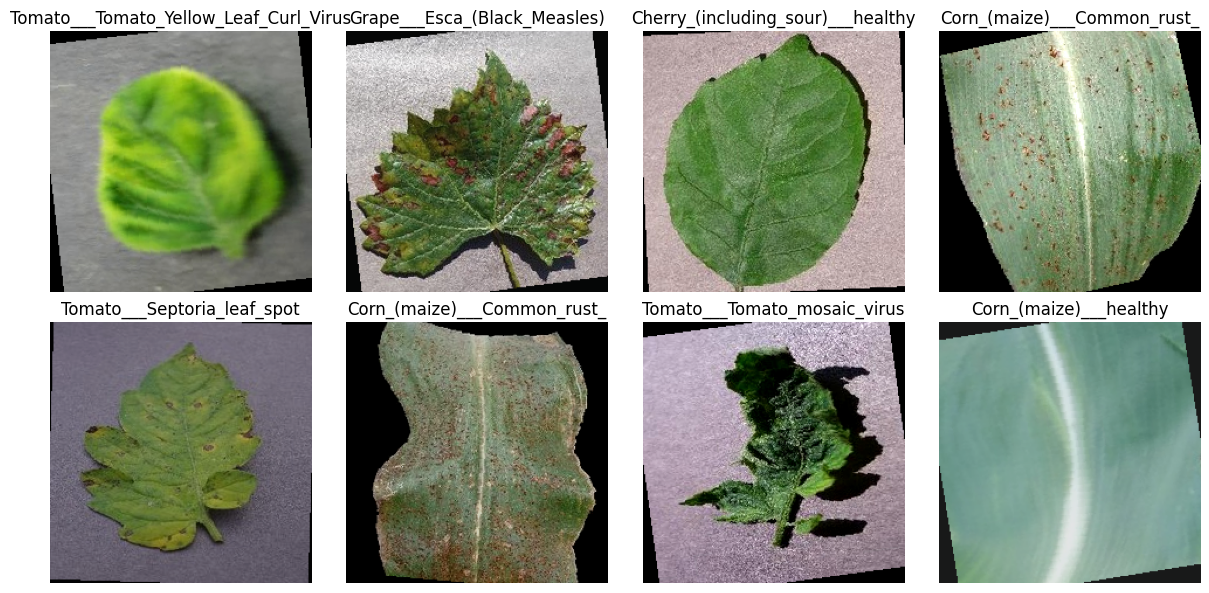

In [4]:
batch_images, batch_labels = next(iter(train_loader))
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for axis, image, label in zip(axes.flat, batch_images[:8], batch_labels[:8]):
    image = image.permute(1, 2, 0).numpy()
    image = np.clip(image * np.asarray(IMAGENET_STD) + np.asarray(IMAGENET_MEAN), 0, 1)
    axis.imshow(image)
    axis.set_title(CLASS_NAMES[label])
    axis.axis('off')
fig.tight_layout()
fig.savefig(RESULTS_DIR / 'sample_images.png', dpi=100, bbox_inches='tight')
plt.show()


## 2 · Model definition

In [5]:
def build_vgg16(num_classes, freeze_base=True):
    model = models.vgg16(weights=models.VGG16_Weights.DEFAULT)
    model.avgpool = nn.AdaptiveAvgPool2d((1, 1))
    model.classifier = nn.Sequential(
        nn.Flatten(),
        nn.Linear(512, 256),
        nn.ReLU(inplace=True),
        nn.Dropout(0.4),
        nn.Linear(256, num_classes),
    )
    if freeze_base:
        for parameter in model.features.parameters():
            parameter.requires_grad = False
    for parameter in model.classifier.parameters():
        parameter.requires_grad = True
    return model


def plain_model(model):
    return model._orig_mod if hasattr(model, '_orig_mod') else model


def count_params(model):
    base = plain_model(model)
    total = sum(parameter.numel() for parameter in base.parameters())
    trainable = sum(parameter.numel() for parameter in base.parameters() if parameter.requires_grad)
    return trainable, total

model = build_vgg16(NUM_CLASSES, freeze_base=True)
trainable, total = count_params(model)
print(f'Trainable: {trainable:,} / {total:,} ({100 * trainable / total:.1f}%)')
if USE_COMPILE:
    model = torch.compile(model)
    print('torch.compile() applied')
model = model.to(DEVICE)
if USE_CHANNELS_LAST:
    model = model.to(memory_format=torch.channels_last)

Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:14<00:00, 38.5MB/s]


Trainable: 141,094 / 14,855,782 (0.9%)


## 3 · Training utilities: AMP, early stopping, and resumable checkpoints

In [6]:
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)


def capture_rng_state():
    state = {'torch_rng_state': torch.get_rng_state(), 'numpy_rng_state': np.random.get_state()}
    if torch.cuda.is_available():
        state['cuda_rng_state_all'] = torch.cuda.get_rng_state_all()
    return state


def restore_rng_state(checkpoint):
    torch.set_rng_state(checkpoint['torch_rng_state'])
    np.random.set_state(checkpoint['numpy_rng_state'])
    if torch.cuda.is_available() and 'cuda_rng_state_all' in checkpoint:
        torch.cuda.set_rng_state_all(checkpoint['cuda_rng_state_all'])


def save_training_checkpoint(path, model, optimizer, scheduler, scaler, phase, epoch, history, best_val_acc, best_model_state):
    payload = {
        'workflow_version': WORKFLOW_VERSION,
        'phase': phase,
        'epoch_completed': epoch,
        'model_state_dict': plain_model(model).state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
        'scheduler_state_dict': scheduler.state_dict() if scheduler else None,
        'scaler_state_dict': scaler.state_dict() if scaler else None,
        'history': history,
        'best_val_acc': best_val_acc,
        'best_model_state_dict': best_model_state,
        **capture_rng_state(),
    }
    path = Path(path)
    temporary_path = path.with_suffix(path.suffix + '.tmp')
    torch.save(payload, temporary_path)
    os.replace(temporary_path, path)
    print(f'  Checkpoint saved: {path.name} (epoch {epoch})')


def load_training_checkpoint(path, model, optimizer, scheduler=None, scaler=None):
    checkpoint = torch.load(path, map_location='cpu', weights_only=False)
    if checkpoint.get('workflow_version') != WORKFLOW_VERSION:
        print(f'Ignoring incompatible checkpoint: {path.name}')
        return None
    plain_model(model).load_state_dict(checkpoint['model_state_dict'])
    optimizer.load_state_dict(checkpoint['optimizer_state_dict'])
    if scheduler is not None and checkpoint.get('scheduler_state_dict') is not None:
        scheduler.load_state_dict(checkpoint['scheduler_state_dict'])
    if scaler is not None and checkpoint.get('scaler_state_dict') is not None:
        scaler.load_state_dict(checkpoint['scaler_state_dict'])
    restore_rng_state(checkpoint)
    print(f"Resuming {checkpoint['phase']} after epoch {checkpoint['epoch_completed']}.")
    return checkpoint


class EarlyStopping:
    def __init__(self, patience=5, min_delta=1e-4):
        self.patience = patience
        self.min_delta = min_delta
        self.counter = 0
        self.best_score = None
        self.best_state = None
        self.stop = False

    def step(self, score, model):
        if self.best_score is None or score > self.best_score + self.min_delta:
            self.best_score = score
            self.best_state = copy.deepcopy(plain_model(model).state_dict())
            self.counter = 0
            return True
        self.counter += 1
        if self.counter >= self.patience:
            self.stop = True
        return False


def train_one_epoch(model, loader, criterion, optimizer, scaler, scheduler=None):
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    optimizer.zero_grad(set_to_none=True)
    for batch_index, (images, labels) in enumerate(tqdm(loader, leave=False, desc='train')):
        images = images.to(DEVICE, non_blocking=True, memory_format=torch.channels_last if USE_CHANNELS_LAST else torch.preserve_format)
        labels = labels.to(DEVICE, non_blocking=True)
        with autocast('cuda', enabled=USE_AMP):
            logits = model(images)
            loss = criterion(logits, labels) / ACCUMULATION_STEPS
        scaler.scale(loss).backward()
        should_step = (batch_index + 1) % ACCUMULATION_STEPS == 0 or batch_index + 1 == len(loader)
        if should_step:
            scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad(set_to_none=True)
            if scheduler is not None:
                scheduler.step()
        running_loss += loss.item() * ACCUMULATION_STEPS * images.size(0)
        correct += (logits.argmax(1) == labels).sum().item()
        total += images.size(0)
    return running_loss / total, correct / total


@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()
    running_loss, correct, total = 0.0, 0, 0
    for images, labels in tqdm(loader, leave=False, desc='eval'):
        images = images.to(DEVICE, non_blocking=True, memory_format=torch.channels_last if USE_CHANNELS_LAST else torch.preserve_format)
        labels = labels.to(DEVICE, non_blocking=True)
        with autocast('cuda', enabled=USE_AMP):
            logits = model(images)
            loss = criterion(logits, labels)
        running_loss += loss.item() * images.size(0)
        correct += (logits.argmax(1) == labels).sum().item()
        total += labels.size(0)
    return running_loss / total, correct / total


def run_phase(model, train_loader, val_loader, criterion, optimizer, scheduler, epochs, phase_name, checkpoint_path, scheduler_per_batch=False):
    scaler = GradScaler('cuda', enabled=USE_AMP)
    history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
    early_stopping = EarlyStopping(patience=EARLY_STOP_PAT)
    start_epoch = 1
    checkpoint_path = Path(checkpoint_path)

    if RESUME and checkpoint_path.exists():
        checkpoint = load_training_checkpoint(checkpoint_path, model, optimizer, scheduler, scaler)
        if checkpoint is not None and checkpoint.get('phase') == phase_name:
            history = checkpoint['history']
            start_epoch = int(checkpoint['epoch_completed']) + 1
            early_stopping.best_score = checkpoint.get('best_val_acc')
            early_stopping.best_state = checkpoint.get('best_model_state_dict')
        elif checkpoint is not None:
            print(f"Checkpoint is for {checkpoint.get('phase')}; starting {phase_name} fresh.")

    for epoch in range(start_epoch, epochs + 1):
        t0 = time.time()
        batch_scheduler = scheduler if scheduler_per_batch else None
        train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer, scaler, batch_scheduler)
        val_loss, val_acc = evaluate(model, val_loader, criterion)
        if scheduler is not None and not scheduler_per_batch:
            if isinstance(scheduler, optim.lr_scheduler.ReduceLROnPlateau):
                scheduler.step(val_loss)
            else:
                scheduler.step()
        history['train_loss'].append(train_loss)
        history['train_acc'].append(train_acc)
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)
        improved = early_stopping.step(val_acc, model)
        save_training_checkpoint(checkpoint_path, model, optimizer, scheduler, scaler, phase_name, epoch, history, early_stopping.best_score, early_stopping.best_state)
        flag = ' best' if improved else f' no improvement {early_stopping.counter}/{early_stopping.patience}'
        print(f'[{phase_name}] Epoch {epoch}/{epochs} | train loss {train_loss:.4f} | val loss {val_loss:.4f} | val acc {val_acc:.4f} | {time.time() - t0:.1f}s{flag}')
        if early_stopping.stop:
            print(f'Early stopping triggered at epoch {epoch}.')
            break

    if early_stopping.best_state is not None:
        plain_model(model).load_state_dict(early_stopping.best_state)
    print(f'[{phase_name}] Best val_acc = {early_stopping.best_score:.4f}')
    return history

## 4 · Phase 1 — Feature extraction (classifier head only)

In [7]:
print('=' * 60)
print('PHASE 1 — Feature extraction (compact head only)')
print('=' * 60)

criterion = nn.CrossEntropyLoss(label_smoothing=LABEL_SMOOTHING)
optimizer_p1 = optim.AdamW(
    filter(lambda parameter: parameter.requires_grad, model.parameters()),
    lr=P1_LR,
    weight_decay=1e-4,
)
scheduler_p1 = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_p1, mode='min', patience=2, factor=0.2
)
history_p1 = run_phase(
    model, train_loader, val_loader, criterion, optimizer_p1, scheduler_p1,
    epochs=P1_EPOCHS, phase_name='P1',
    checkpoint_path=CHECKPOINT_DIR / 'phase1_latest.pt',
)
torch.save(plain_model(model).state_dict(), MODELS_DIR / 'vgg16_phase1.pth')
print('Phase 1 weights saved.')

PHASE 1 — Feature extraction (compact head only)


train:   0%|          | 0/476 [00:00<?, ?it/s]

eval:   0%|          | 0/102 [00:00<?, ?it/s]

  Checkpoint saved: phase1_latest.pt (epoch 1)
[P1] Epoch 1/15 | train loss 1.3937 | val loss 0.5627 | val acc 0.8539 | 171.5s best


train:   0%|          | 0/476 [00:00<?, ?it/s]

eval:   0%|          | 0/102 [00:00<?, ?it/s]

... (36 outputs left out)

  Checkpoint saved: phase1_latest.pt (epoch 14)
[P1] Epoch 14/15 | train loss 0.2089 | val loss 0.1556 | val acc 0.9489 | 164.6s best


train:   0%|          | 0/476 [00:00<?, ?it/s]

eval:   0%|          | 0/102 [00:00<?, ?it/s]

  Checkpoint saved: phase1_latest.pt (epoch 15)
[P1] Epoch 15/15 | train loss 0.2092 | val loss 0.1557 | val acc 0.9489 | 165.8s no improvement 1/5
[P1] Best val_acc = 0.9489
Phase 1 weights saved.


## 5 · Phase 2 — Fine-tuning (final VGG16 feature block + classifier)

In [8]:
base = plain_model(model)
for parameter in base.parameters():
    parameter.requires_grad = False
for parameter in base.features[UNFREEZE_FROM:].parameters():
    parameter.requires_grad = True
for parameter in base.classifier.parameters():
    parameter.requires_grad = True
trainable, total = count_params(model)
print(f'Unfrozen: features[{UNFREEZE_FROM}:] (VGG16 block 5) + compact classifier')
print(f'Trainable: {trainable:,} / {total:,} ({100 * trainable / total:.1f}%)')

Unfrozen: features[24:] (VGG16 block 5) + compact classifier
Trainable: 7,220,518 / 14,855,782 (48.6%)


In [9]:
print('=' * 60)
print('PHASE 2 — Fine-tuning VGG16 block 5 + classifier')
print('=' * 60)

optimizer_p2 = optim.AdamW([
    {'params': base.features[UNFREEZE_FROM:].parameters(), 'lr': P2_BACKBONE_LR},
    {'params': base.classifier.parameters(), 'lr': P2_HEAD_LR},
], weight_decay=1e-4)
steps_per_epoch = (len(train_loader) + ACCUMULATION_STEPS - 1) // ACCUMULATION_STEPS
scheduler_p2 = optim.lr_scheduler.OneCycleLR(
    optimizer_p2,
    max_lr=[P2_BACKBONE_LR, P2_HEAD_LR],
    steps_per_epoch=steps_per_epoch,
    epochs=P2_EPOCHS,
    pct_start=0.2,
    anneal_strategy='cos',
)
history_p2 = run_phase(
    model, train_loader, val_loader, criterion, optimizer_p2, scheduler_p2,
    epochs=P2_EPOCHS, phase_name='P2',
    checkpoint_path=CHECKPOINT_DIR / 'phase2_latest.pt',
    scheduler_per_batch=True,
)
torch.save(plain_model(model).state_dict(), MODELS_DIR / 'vgg16_best.pth')
print('Best fine-tuned weights saved.')

PHASE 2 — Fine-tuning VGG16 block 5 + classifier


train:   0%|          | 0/476 [00:00<?, ?it/s]

eval:   0%|          | 0/102 [00:00<?, ?it/s]

  Checkpoint saved: phase2_latest.pt (epoch 1)
[P2] Epoch 1/15 | train loss 0.1826 | val loss 0.1369 | val acc 0.9540 | 164.8s best


train:   0%|          | 0/476 [00:00<?, ?it/s]

eval:   0%|          | 0/102 [00:00<?, ?it/s]

... (36 outputs left out)

  Checkpoint saved: phase2_latest.pt (epoch 14)
[P2] Epoch 14/15 | train loss 0.0544 | val loss 0.0596 | val acc 0.9808 | 166.9s no improvement 3/5


train:   0%|          | 0/476 [00:00<?, ?it/s]

eval:   0%|          | 0/102 [00:00<?, ?it/s]

  Checkpoint saved: phase2_latest.pt (epoch 15)
[P2] Epoch 15/15 | train loss 0.0549 | val loss 0.0596 | val acc 0.9808 | 166.7s no improvement 4/5
[P2] Best val_acc = 0.9810
Best fine-tuned weights saved.


## 6 · Training curves

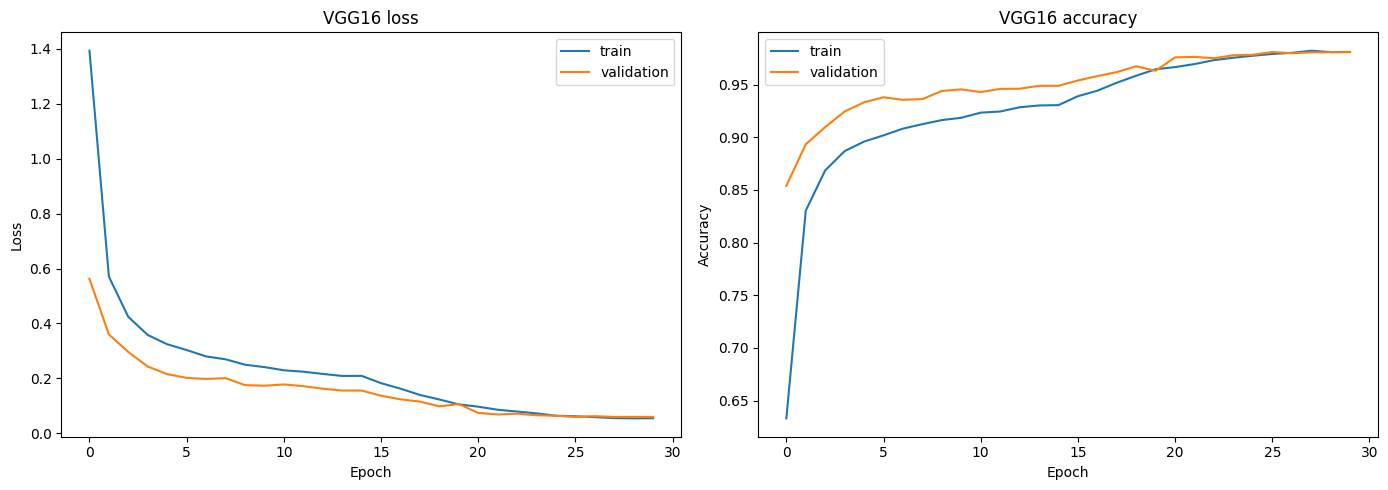

In [10]:
def combined_history(key):
    return history_p1[key] + history_p2[key]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(combined_history('train_loss'), label='train')
axes[0].plot(combined_history('val_loss'), label='validation')
axes[0].set(title='VGG16 loss', xlabel='Epoch', ylabel='Loss')
axes[1].plot(combined_history('train_acc'), label='train')
axes[1].plot(combined_history('val_acc'), label='validation')
axes[1].set(title='VGG16 accuracy', xlabel='Epoch', ylabel='Accuracy')
for axis in axes:
    axis.legend()
fig.tight_layout()
fig.savefig(RESULTS_DIR / 'training_curves.png', dpi=120, bbox_inches='tight')
plt.show()


## 7 · Test evaluation

In [11]:
model.eval()
y_true, y_pred = [], []
with torch.no_grad():
    for images, labels in tqdm(test_loader, desc='test', leave=False):
        logits = model(images.to(DEVICE, non_blocking=True))
        y_pred.extend(logits.argmax(1).cpu().numpy())
        y_true.extend(labels.numpy())

test_acc = accuracy_score(y_true, y_pred)
test_f1 = f1_score(y_true, y_pred, average='macro')
report = classification_report(y_true, y_pred, target_names=CLASS_NAMES, zero_division=0)
(RESULTS_DIR / 'classification_report.txt').write_text(report, encoding='utf-8')
print(report)
print(f'Test accuracy: {test_acc:.4f}')
print(f'Test macro F1: {test_f1:.4f}')


test:   0%|          | 0/102 [00:00<?, ?it/s]

                                                    precision    recall  f1-score   support

                                Apple___Apple_scab       0.99      0.99      0.99        75
                                 Apple___Black_rot       0.97      0.99      0.98        75
                          Apple___Cedar_apple_rust       1.00      0.97      0.98        33
                                   Apple___healthy       0.99      0.99      0.99       198
                               Blueberry___healthy       0.99      1.00      1.00       181
          Cherry_(including_sour)___Powdery_mildew       0.99      0.99      0.99       127
                 Cherry_(including_sour)___healthy       1.00      0.99      1.00       102
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot       0.86      0.89      0.87        61
                       Corn_(maize)___Common_rust_       1.00      0.99      0.99       143
               Corn_(maize)___Northern_Leaf_Blight       0.93      0.93      0.

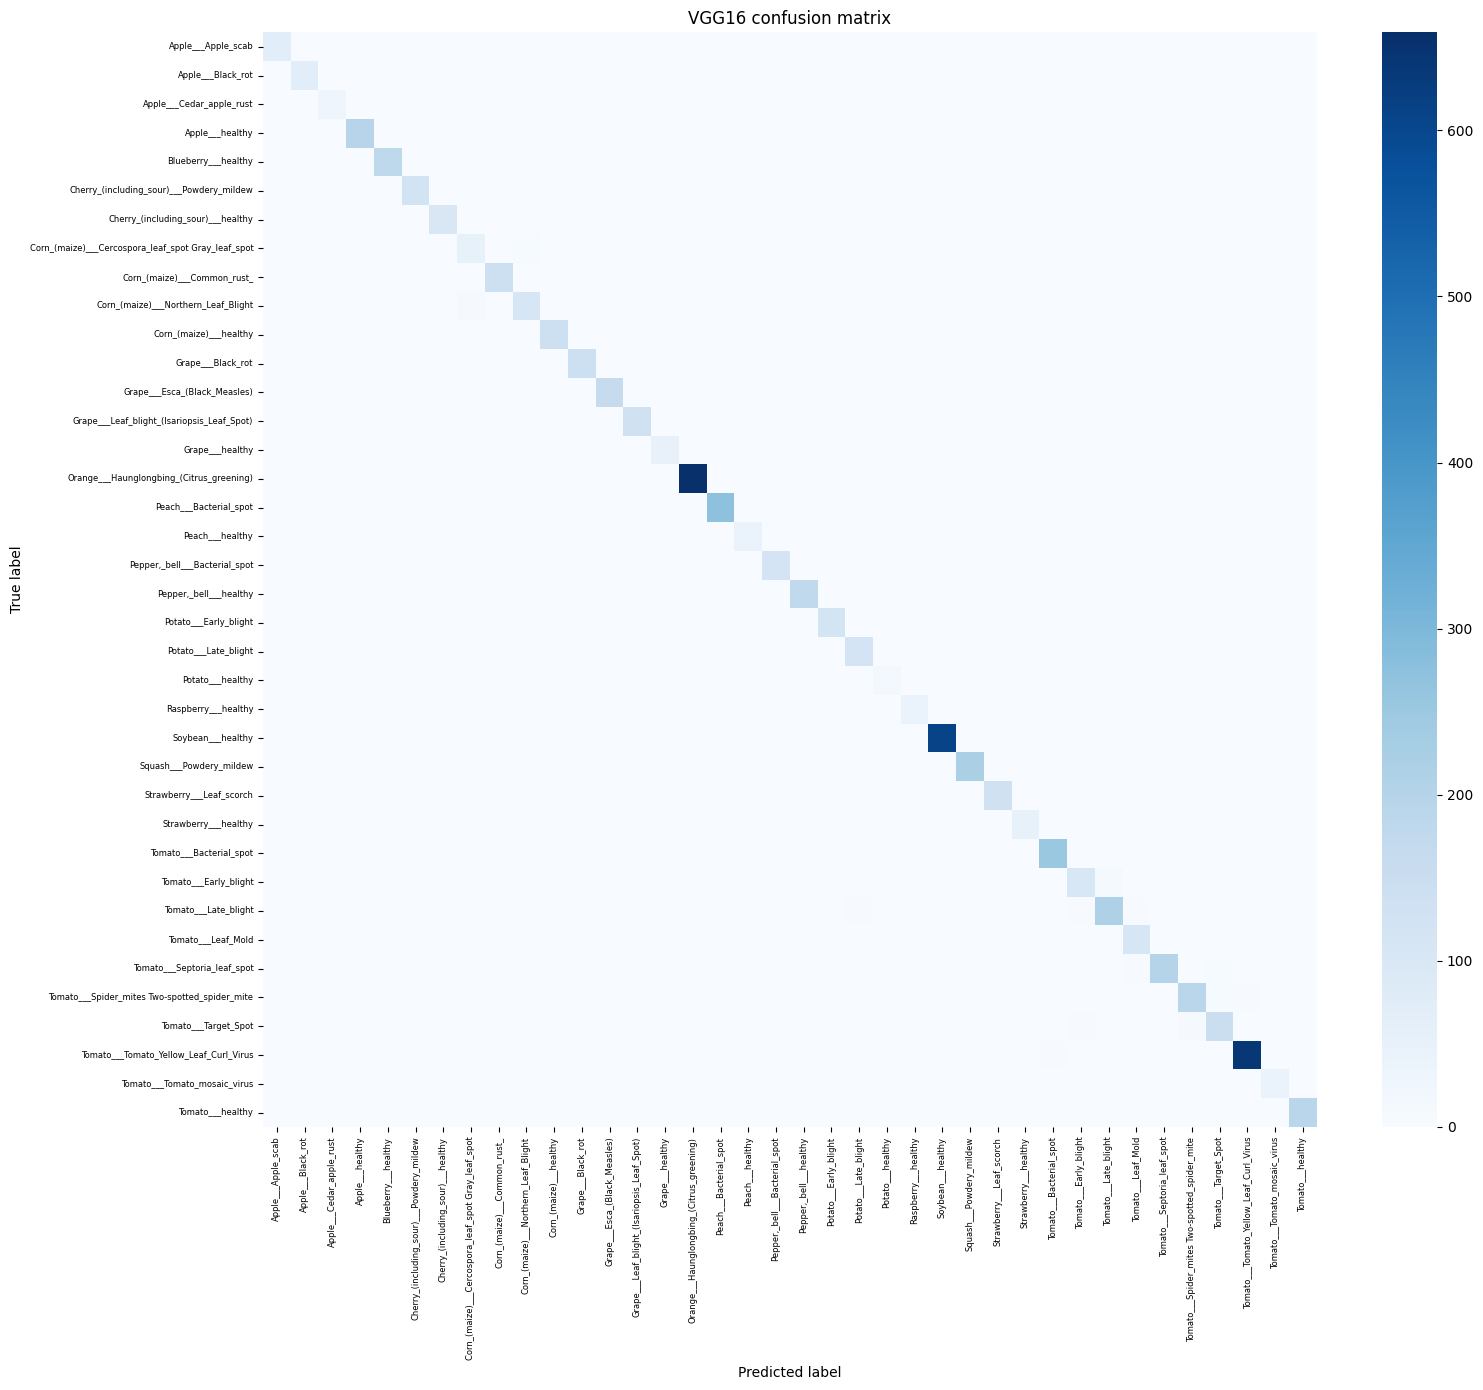

In [12]:
cm = confusion_matrix(y_true, y_pred)
fig, axis = plt.subplots(figsize=(16, 14))
sns.heatmap(cm, cmap='Blues', ax=axis, xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
axis.set(title='VGG16 confusion matrix', xlabel='Predicted label', ylabel='True label')
plt.xticks(rotation=90, fontsize=6)
plt.yticks(fontsize=6)
fig.tight_layout()
fig.savefig(RESULTS_DIR / 'confusion_matrix.png', dpi=120, bbox_inches='tight')
plt.show()


In [13]:
metrics = {
    'model': 'VGG16',
    'test_accuracy': float(test_acc),
    'test_f1_macro': float(test_f1),
    'phase1_best_val_accuracy': float(max(history_p1['val_acc'])),
    'phase2_best_val_accuracy': float(max(history_p2['val_acc'])),
    'classes': CLASS_NAMES,
    'training_history': {'phase1': history_p1, 'phase2': history_p2},
}
(RESULTS_DIR / 'metrics.json').write_text(json.dumps(metrics, indent=2), encoding='utf-8')
print(json.dumps(metrics, indent=2))


{
  "model": "VGG16",
  "test_accuracy": 0.9817344589409056,
  "test_f1_macro": 0.9757218065661434,
  "phase1_best_val_accuracy": 0.948902869418444,
  "phase2_best_val_accuracy": 0.9809728402639252,
  "classes": [
    "Apple___Apple_scab",
    "Apple___Black_rot",
    "Apple___Cedar_apple_rust",
    "Apple___healthy",
    "Blueberry___healthy",
    "Cherry_(including_sour)___Powdery_mildew",
    "Cherry_(including_sour)___healthy",
    "Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot",
    "Corn_(maize)___Common_rust_",
    "Corn_(maize)___Northern_Leaf_Blight",
    "Corn_(maize)___healthy",
    "Grape___Black_rot",
    "Grape___Esca_(Black_Measles)",
    "Grape___Leaf_blight_(Isariopsis_Leaf_Spot)",
    "Grape___healthy",
    "Orange___Haunglongbing_(Citrus_greening)",
    "Peach___Bacterial_spot",
    "Peach___healthy",
    "Pepper,_bell___Bacterial_spot",
    "Pepper,_bell___healthy",
    "Potato___Early_blight",
    "Potato___Late_blight",
    "Potato___healthy",
    "Raspberry_

## Workflow summary

| Phase | Trainable layers | Optimizer | Learning rate | Scheduler |
|---|---|---|---|---|
| Phase 1 | Compact classifier head | AdamW | 1e-3 | ReduceLROnPlateau |
| Phase 2 | VGG16 block 5 + classifier | AdamW | 1e-5 / 1e-4 | OneCycleLR per optimizer step |

The notebook stages the dataset from `MyDrive/AgroDetect/new_preprocess_dataset_plantvillage` to the Colab local SSD and stores resumable checkpoints under `MyDrive/AgroDetect/VGG16/checkpoints`.